# Matplotlib Tutorial: Customizing Charts With a Real Spotify Dataset

You can access the [Spotify dataset](https://www.kaggle.com/datasets/joebeachcapital/30000-spotify-songs) and read the complete [Medium blog](https://medium.com/@bskky001/matplotlib-tutorial-customizing-charts-with-a-real-spotify-dataset-13e43b78b825) to learn more about Matplotlib and data visualization.

# Dataset Exploration

## Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Read Data

In [ ]:
df = pd.read_csv("spotify_songs.csv")
df.shape

(32833, 23)

## Information About The Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

## Dataset Shape

In [ ]:
df.dropna(inplace=True)
df.shape

(32828, 23)

## First 5 Rows

In [ ]:
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


# Line Chart: Average Song Duration Over Time

## Creating a Basic Line Chart

Before creating the line chart, we need to prepare the data. The release dates are stored as strings, so we'll convert them into datetime objects and extract the release year. Then, we'll calculate the average song duration for each year and convert it from milliseconds to minutes. These steps give us the yearly averages needed to visualize how song duration has changed over time.

In [ ]:
# Convert release dates to datetime objects
df["release_date_parsed"] = pd.to_datetime(
    df["track_album_release_date"],
    errors="coerce"
)

# Extract the release year
df["release_year"] = df["release_date_parsed"].dt.year

# Calculate average song duration in minutes for each year
yearly_duration = (
    df.groupby("release_year")["duration_ms"].mean() / 1000 / 60
)

# Extract years and average durations for plotting
years = yearly_duration.index
average_duration = yearly_duration.values

Then we use plt.plot() to connect the values and reveal the overall trend.

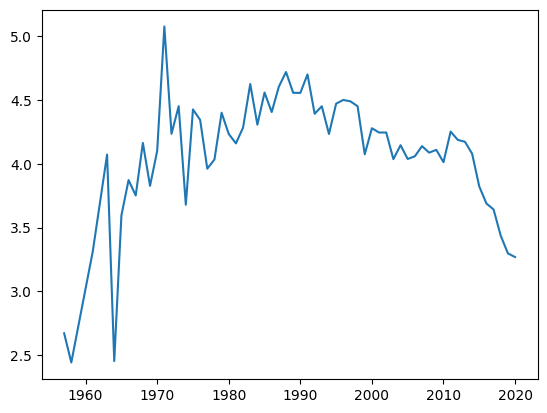

In [ ]:
plt.plot(years, average_duration)
plt.show()

The plt.plot() function creates a line plot using years for the x-axis and average_duration for the y-axis. Matplotlib connects the data points in the order they are provided, making it easier to observe changes over time.

## Adding Markers and Customizing the Line

We can make individual data points more visible by adding markers and adjusting the line's appearance.

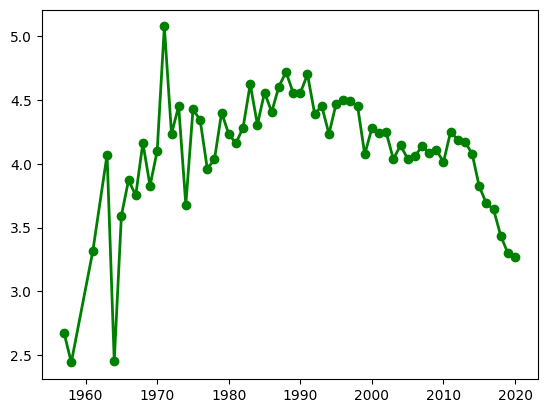

In [ ]:
plt.plot(
    years,
    average_duration,
    marker="o",
    color="green",
    linestyle="-",
    linewidth=2
)
plt.show()

Let's look at what each parameter does:

* marker="o" adds a circular marker at each data point.

* color="green" changes the line and marker color to green.

* linestyle="-" creates a solid line. Other options include "--" for dashed lines and ":" for dotted lines.

* linewidth=2 controls the thickness of the line.

These options help distinguish the data points and make the trend easier to follow.

## Adding a Title and Axis Labels
A chart should clearly communicate what it represents. We can add a descriptive title and labels to explain both axes.

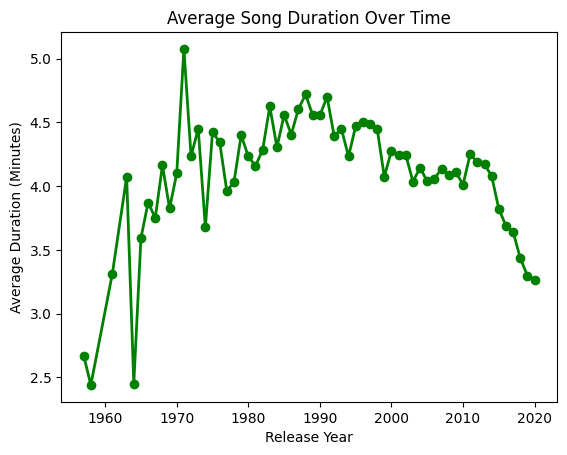

In [ ]:
plt.plot(
    years,
    average_duration,
    marker="o",
    color="green",
    linestyle="-",
    linewidth=2
)
plt.title("Average Song Duration Over Time")
plt.xlabel("Release Year")
plt.ylabel("Average Duration (Minutes)")
plt.show()

* plt.title() adds a title that describes the chart.
* plt.xlabel() labels the horizontal axis.
* plt.ylabel() labels the vertical axis, including the unit of measurement.

Clear labels help readers understand the visualization without needing additional explanation.

## Adding Gridlines
Gridlines make it easier to estimate values and compare points across the chart.

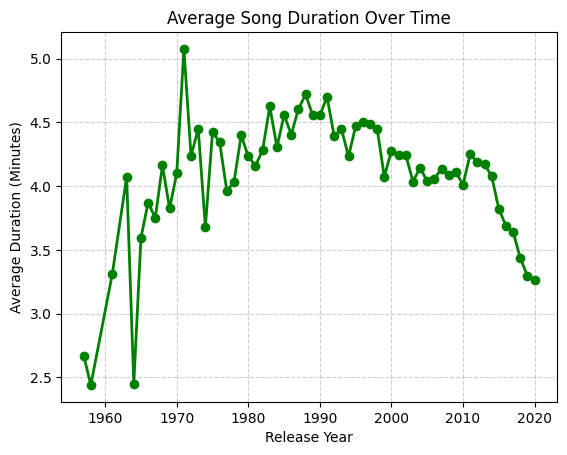

In [ ]:
plt.plot(
    years,
    average_duration,
    marker="o",
    color="green",
    linestyle="-",
    linewidth=2
)
plt.title("Average Song Duration Over Time")
plt.xlabel("Release Year")
plt.ylabel("Average Duration (Minutes)")
plt.grid(
    True,
    linestyle="--",
    alpha=0.6
)
plt.show()

Here, plt.grid() adds gridlines to the plot.
* linestyle="--" makes the gridlines dashed.
* alpha=0.6 controls their transparency. Lower values make gridlines more transparent, preventing them from competing with the data.

Gridlines are useful when they improve readability, but they should remain subtle.

## A More Polished Line Chart
Finally, we can combine these customizations into one complete visualization.

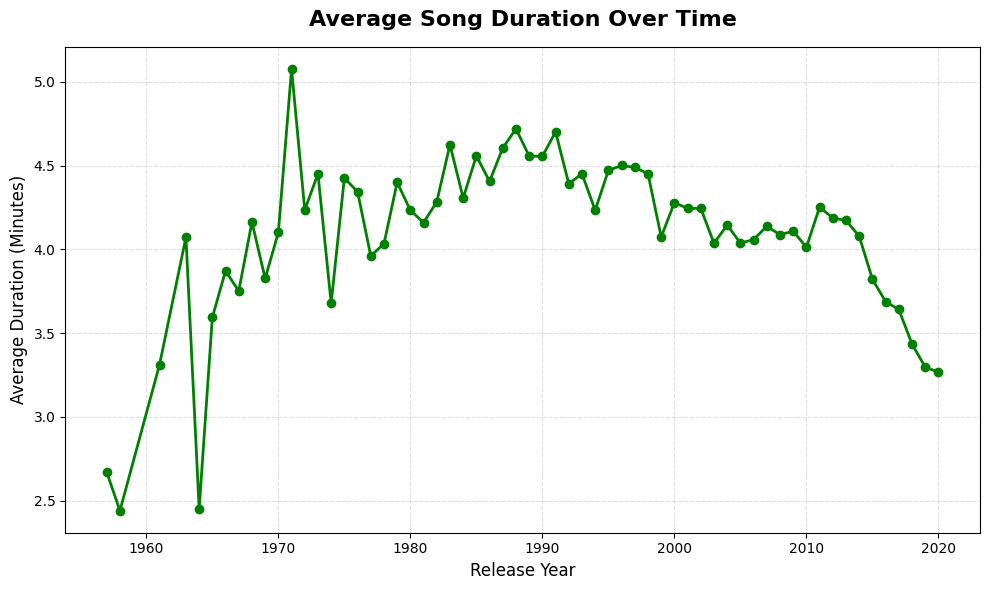

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(
    years,
    average_duration,
    marker="o",
    color="green",
    linestyle="-",
    linewidth=2
)
plt.title(
    "Average Song Duration Over Time",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Average Duration (Minutes)", fontsize=12)
plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)
plt.tight_layout()
plt.show()

We have introduced three additional options:
* figsize=(10, 6) sets the figure's width and height in inches.
* fontsize=16 increases the title's text size, while fontweight="bold" makes it bold.
* pad=15 adds space between the title and the plot area.
* plt.tight_layout() adjusts the spacing to help prevent labels and other elements from overlapping.

The result is a more polished visualization that presents the trend clearly while keeping the design simple.

The same approach can be applied to other chart types. Start with a basic plot, identify what could make it easier to read, and add only the customizations that serve a purpose.

# Bar Chart: Average Speechiness Across Genres

## Creating a Basic Bar Chart
First, we can group the dataset by playlist_genre, calculate the average speechiness for each genre using .mean(), and then sort the results in ascending order using .sort_values().

The result is a Pandas Series containing each genre and its average speechiness, ordered from lowest to highest.

In [ ]:
genre_speechiness = df.groupby("playlist_genre")["speechiness"].mean().sort_values()

Then, we can then create a basic bar chart using Matplotlib.

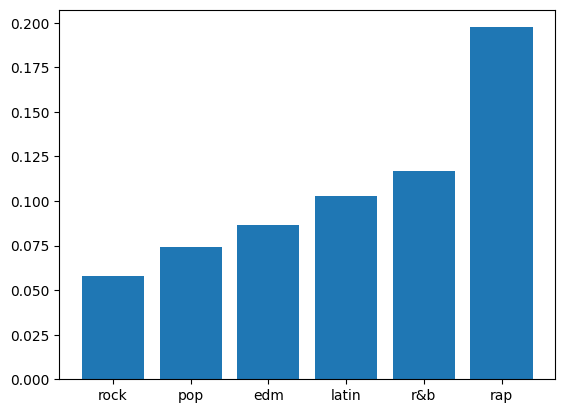

In [ ]:
plt.bar(
    genre_speechiness.index,
    genre_speechiness.values
)
plt.show()

The result gives us a visual comparison of the speechiness of songs in each genre.

## Adjusting the Figure Size
We can control the size of our figure using figsize.

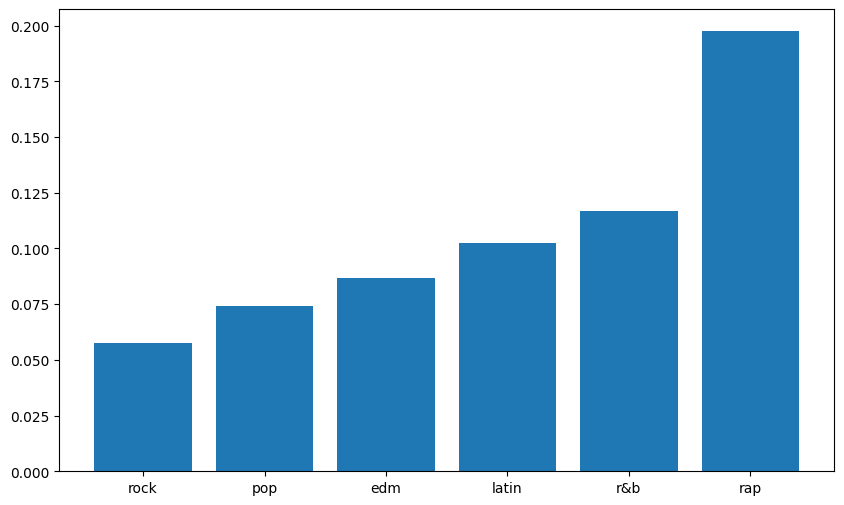

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    genre_speechiness.index,
    genre_speechiness.values
)
plt.show()

The first value represents the width and the second represents the height, both measured in inches.

Increasing the figure size can make labels and other elements easier to read, especially when we have several categories.

## Adding a Title and Axis Labels
A chart should tell the reader what they are looking at without requiring them to guess.

We can add a title and labels to both axes.

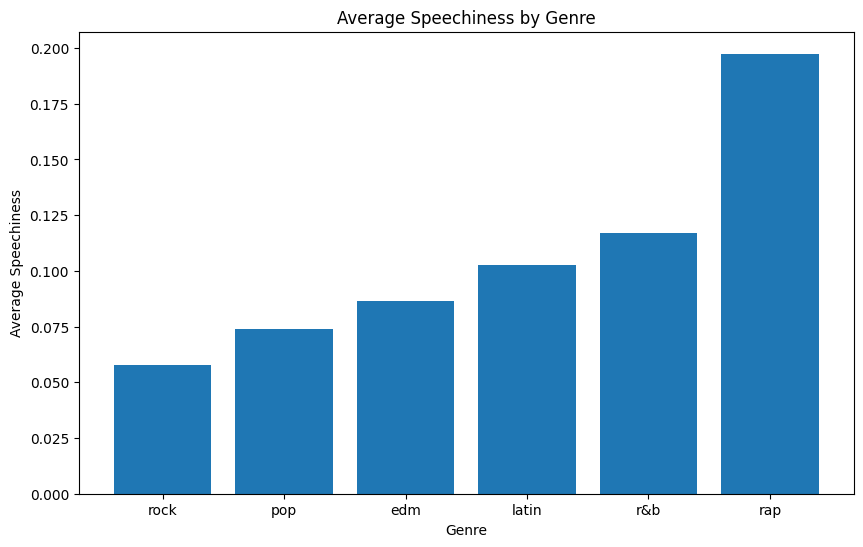

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    genre_speechiness.index,
    genre_speechiness.values
)
plt.title("Average Speechiness by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Speechiness")
plt.show()

Now the purpose of the visualization is immediately clear.

## Making the Labels Easier to Read
If we have many genres, the category names on the x-axis can overlap.

We can rotate them using plt.xticks().

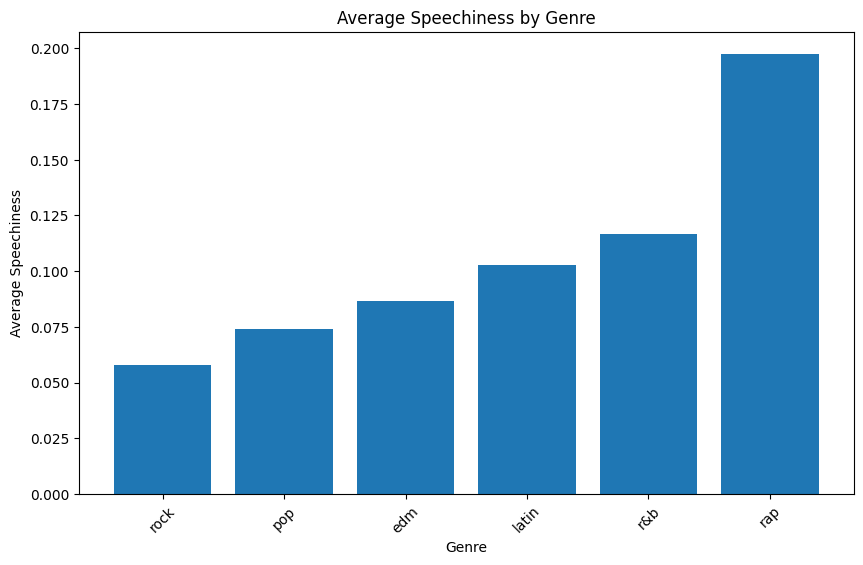

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    genre_speechiness.index,
    genre_speechiness.values
)
plt.title("Average Speechiness by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Speechiness")
plt.xticks(rotation=45)
plt.show()

Although we don't need this adjustment in our example, it can be useful when working with charts that contain many categories. A small adjustment like this can make a significant difference in readability.

## Customizing the Bars
Matplotlib also allows us to control the appearance of the bars.

For example, we can change their color.

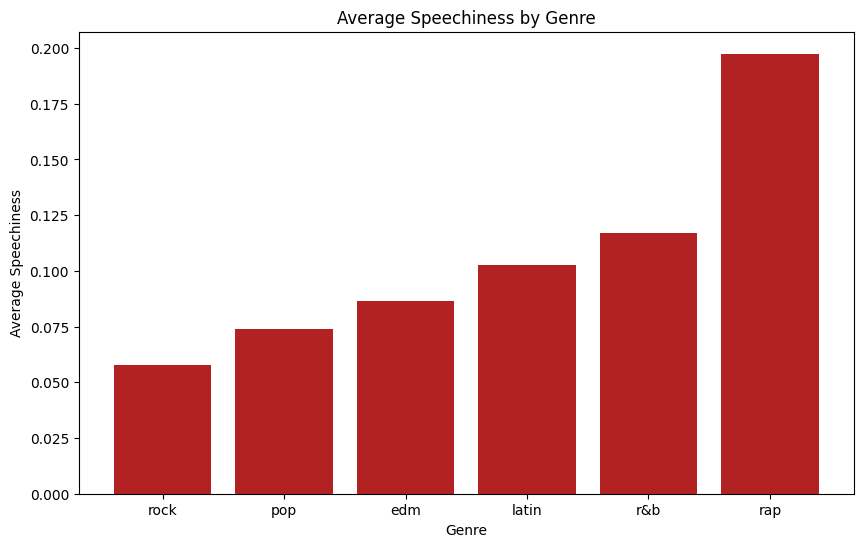

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    genre_speechiness.index,
    genre_speechiness.values,
    color="firebrick"
)
plt.title("Average Speechiness by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Speechiness")
plt.show()

We could also adjust other properties such as transparency using alpha or add borders using edgecolor.

The important thing to remember is that customization should serve a purpose. Adding colors or effects simply to make a chart more decorative does not necessarily make it more effective.

## When There Are Many Categories
If the dataset contains many genres, a vertical bar chart can become difficult to read. In that case, a horizontal bar chart can be a better choice.

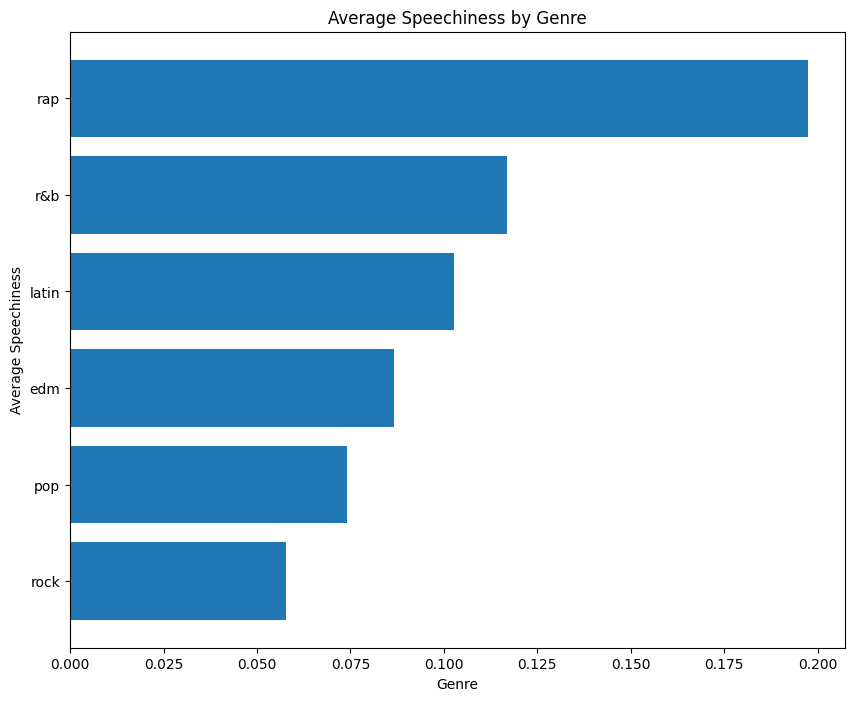

In [ ]:
plt.figure(figsize=(10, 8))
plt.barh(
    genre_speechiness.index,
    genre_speechiness.values
)
plt.title("Average Speechiness by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Speechiness")
plt.show()

Horizontal bars give category names more room and can make comparisons easier.

## A More Polished Bar Chart

We have gradually improved our chart by adjusting its size, labels, orientation, and other visual properties. We can now combine these ideas into a more polished version.

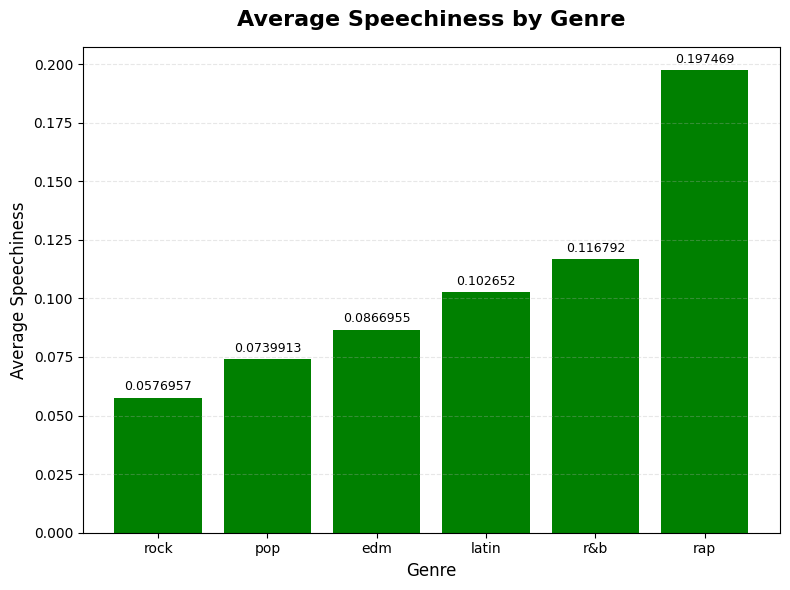

In [ ]:
plt.figure(figsize=(8, 6))
bars = plt.bar(
    genre_speechiness.index,
    genre_speechiness.values,
    color="green"
)
plt.title(
    "Average Speechiness by Genre",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Genre", fontsize=12)
plt.ylabel("Average Speechiness", fontsize=12)
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)
plt.bar_label(
    bars,
    padding=3,
    fontsize=9
)
plt.tight_layout()
plt.show()

There are a few additional elements here that make the visualization easier to read.

fontsize and fontweight make the title and labels more prominent.
pad adds some space between the title and the chart.

- grid() adds subtle reference lines that make it easier to compare the bars.
- bar_label() displays the exact number of songs at the end of each bar.
- tight_layout() helps prevent labels and other elements from being cut off.

The goal of these adjustments is not to make the chart more decorative. Each element should help the reader understand the data more easily.

# Histogram: Distribution of Song Durations

## Creating a Basic Histogram
First we need to convert durations from milliseconds to minutes.

In [ ]:
# Convert durations from milliseconds to minutes
duration_mins = df["duration_ms"] / 1000 / 60

Then we can create a histogram with Matplotlib using plt.hist().

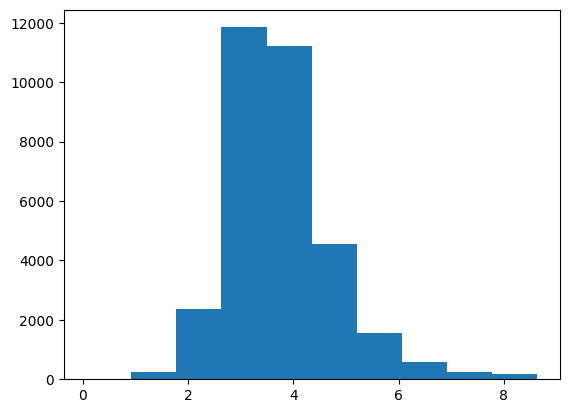

In [ ]:
plt.hist(duration_mins)
plt.show()

Unlike a bar chart, where each bar represents a distinct category, the bars in a histogram represent ranges of numerical values, called bins.

For example, one bin might cover song durations from 0 to 2 minutes, another from 2 to 4 minutes, and so on.

## Choosing the Number of Bins
We can control the number of bins with the bins parameter.

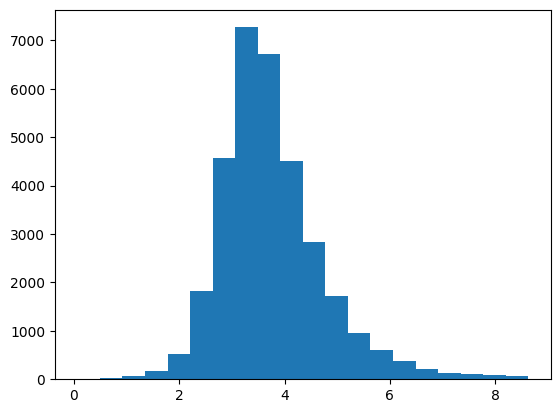

In [ ]:
plt.hist(
    duration_mins,
    bins=20
)
plt.show()

The number of bins affects how much detail we can see.

With too few bins, important patterns may be hidden because many observations are grouped together. With too many bins, the distribution can become noisy and difficult to interpret.

There is no single number of bins that is always correct. The appropriate choice depends on the dataset and what we are trying to communicate.

## Adding Labels
Let's make the purpose of the chart clearer.

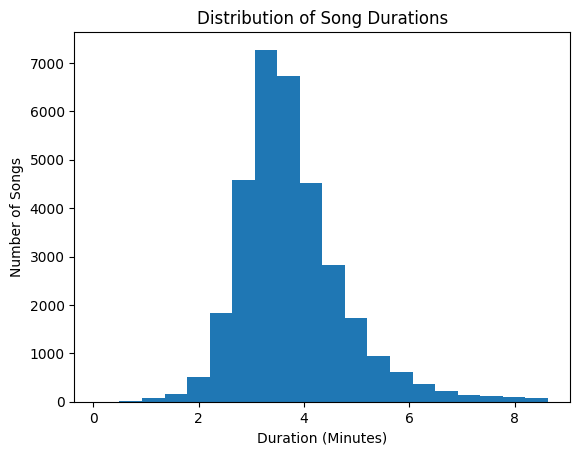

In [ ]:
plt.hist(
    duration_mins,
    bins=20
)
plt.title("Distribution of Song Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Songs")
plt.show()

Now the reader can immediately understand what each axis represents.

## Adding Transparency and Gridlines
We can further improve readability by adjusting the transparency of the bars and adding subtle gridlines.

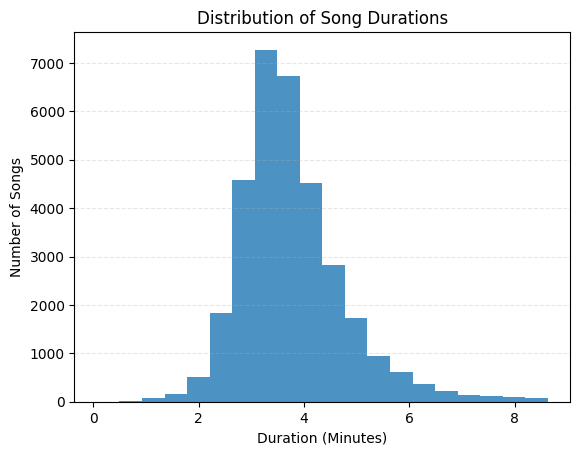

In [ ]:
plt.hist(
    duration_mins,
    bins=20,
    alpha=0.8
)
plt.title("Distribution of Song Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Songs")
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)
plt.show()

The alpha parameter controls transparency, with values between 0 and 1. A lower value makes the bars more transparent.

The gridlines help the reader compare the height of the bars against the y-axis.

## A More Polished Histogram
We can now combine these elements into a more polished visualization.

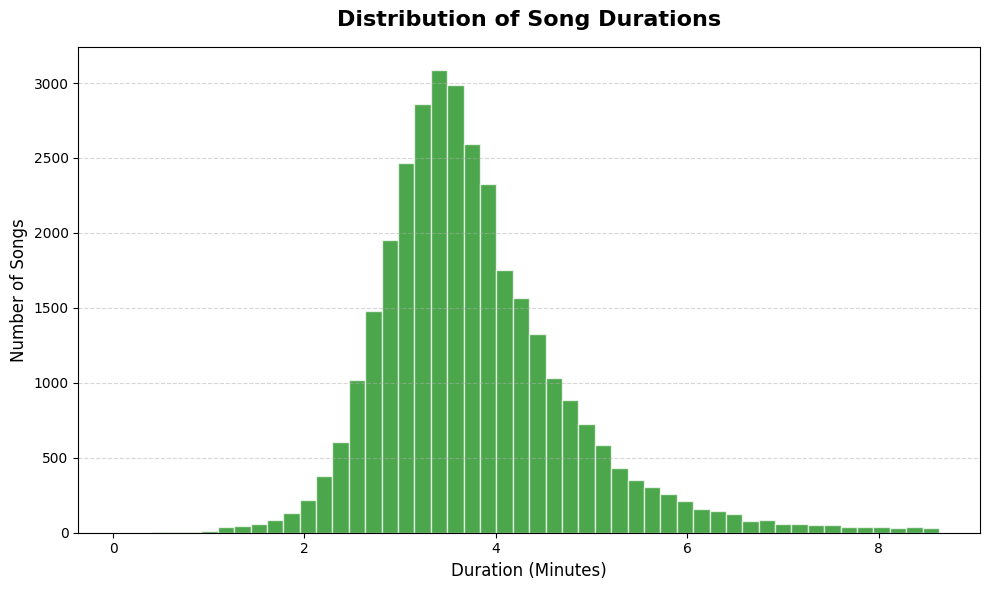

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(
    duration_mins,
    bins=50,
    color="green",
    edgecolor="white",
    alpha=0.7
)
plt.title(
    "Distribution of Song Durations",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Duration (Minutes)", fontsize=12)
plt.ylabel("Number of Songs", fontsize=12)
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)
plt.tight_layout()
plt.show()

Instead of examining 32,000 individual songs, we can see how their durations are distributed across different intervals and identify where songs are most concentrated.

This is one of the main advantages of data visualization: it transforms thousands of individual observations into a visual summary that is much easier to interpret.

## A Small but Important Distinction
It is easy to confuse histograms with bar charts because both use rectangular bars. The key difference is what those bars represent.
- Bar chart:
 Categories → Number of observations
- Histogram:
 Numerical ranges → Number of observations

For example, in our previous chart, each bar represented a genre. In this chart, each bar represents a range of duration.

# Scatter Plot: Relationship Between Energy and Popularity

## Creating a Basic Scatter Plot
We can create a scatter plot using plt.scatter().

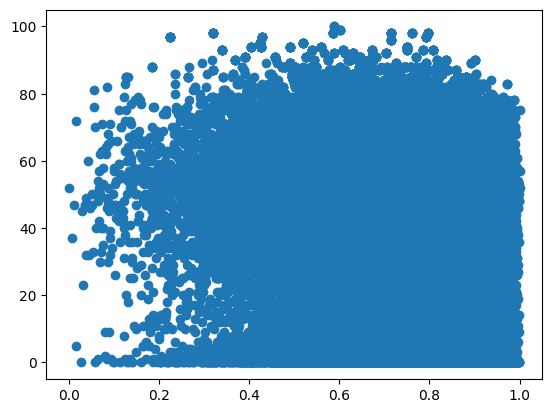

In [ ]:
plt.scatter(
    df["energy"],
    df["track_popularity"]
)
plt.show()

Each point represents one song. The x-axis shows the song's energy, while the y-axis shows its popularity.

However, our dataset contains approximately 32,000 observations. Plotting this many points can result in substantial overlap, making the chart difficult to interpret.

## Making Dense Scatter Plots Easier to Read
One way to address overlapping points is to make the markers smaller and more transparent.

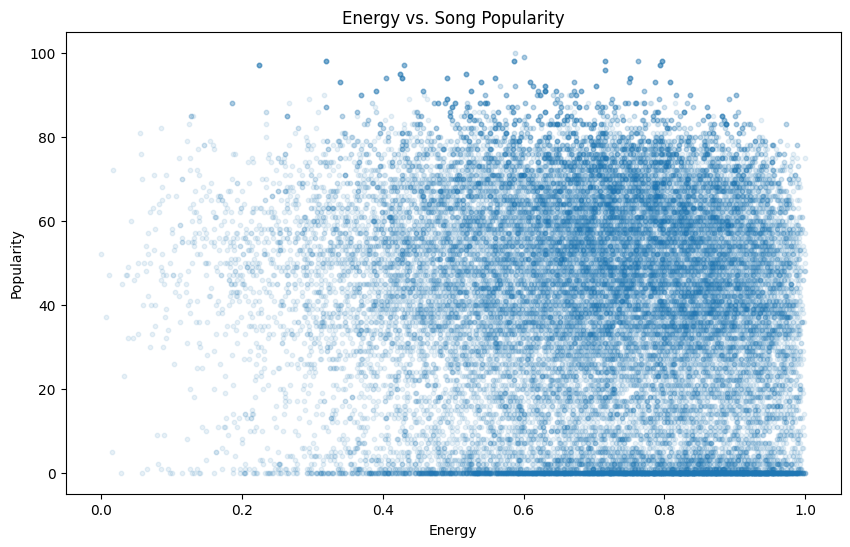

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df["energy"],
    df["track_popularity"],
    s=10,
    alpha=0.1
)
plt.title("Energy vs. Song Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity")
plt.show()

The s parameter controls the marker size, while alpha controls transparency.

When many points overlap, transparency can be particularly useful. Areas containing many observations become visually darker, allowing us to see where the data is concentrated.

## Adding a Trend Line
The scatter plot shows the individual observations, but we may also want to understand the overall direction of the relationship.

We can calculate a correlation coefficient:

In [ ]:
correlation = df["energy"].corr(df["track_popularity"])
print(round(correlation, 2))

-0.11


The correlation coefficient ranges from -1 to 1:

- A value close to 1 indicates a strong positive linear relationship.
- A value close to -1 indicates a strong negative linear relationship.
- A value close to 0 indicates little or no linear relationship.

We can also add a simple trend line using NumPy.

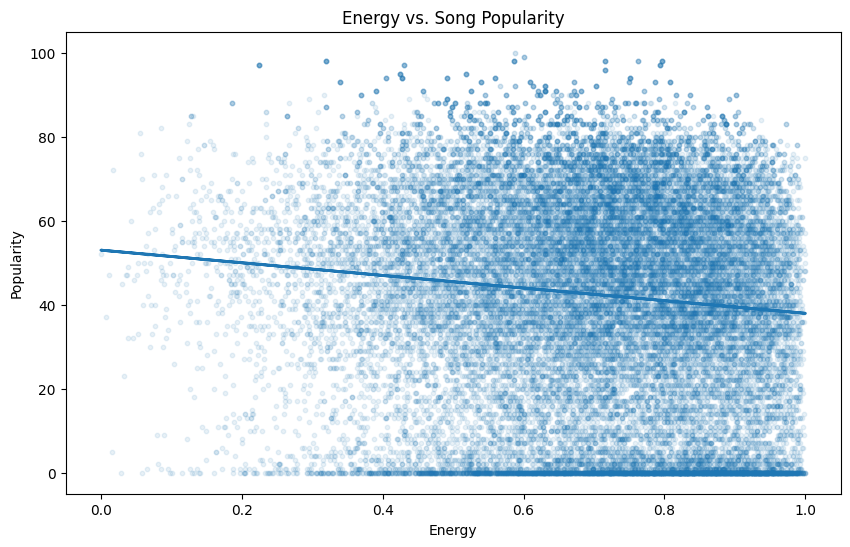

In [ ]:
import numpy as np
x = df["energy"]
y = df["track_popularity"]
m, b = np.polyfit(x, y, 1)
plt.figure(figsize=(10, 6))
plt.scatter(
    x,
    y,
    s=10,
    alpha=0.1
)
plt.plot(
    x,
    m * x + b,
    linewidth=2
)
plt.title("Energy vs. Song Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity")
plt.show()

The line represents the overall linear trend in the data.

However, it is important to remember that correlation does not imply causation. Even if we observe a positive relationship between energy and popularity, this does not mean that increasing a song's energy will necessarily make it more popular.

## Making the Relationship Easier to Interpret
With 32,000 songs, even a transparent scatter plot can still be difficult to interpret. Another approach is to group songs into energy ranges and compare their average popularity.

For example, we can divide energy into five groups.

In [ ]:
df["energy_group"] = pd.cut(
    df["energy"],
    bins=5
)

Then calculate the average popularity for each group:

In [ ]:
avg_popularity = (
    df.groupby(
        "energy_group",
        observed=True
    )["track_popularity"]
    .mean()
)

We can visualize these averages with a bar chart:

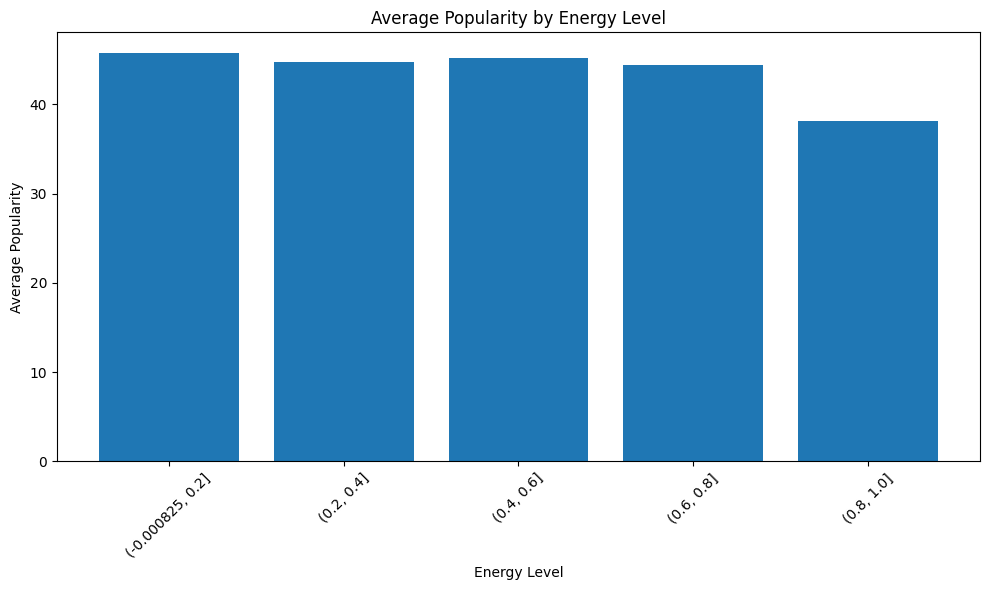

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    avg_popularity.index.astype(str),
    avg_popularity.values
)
plt.title("Average Popularity by Energy Level")
plt.xlabel("Energy Level")
plt.ylabel("Average Popularity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This visualization sacrifices the individual observations, but it makes the comparison much easier to see.

## A More Polished Scatter Plot
We can now combine our Matplotlib techniques into a cleaner version of the original scatter plot.

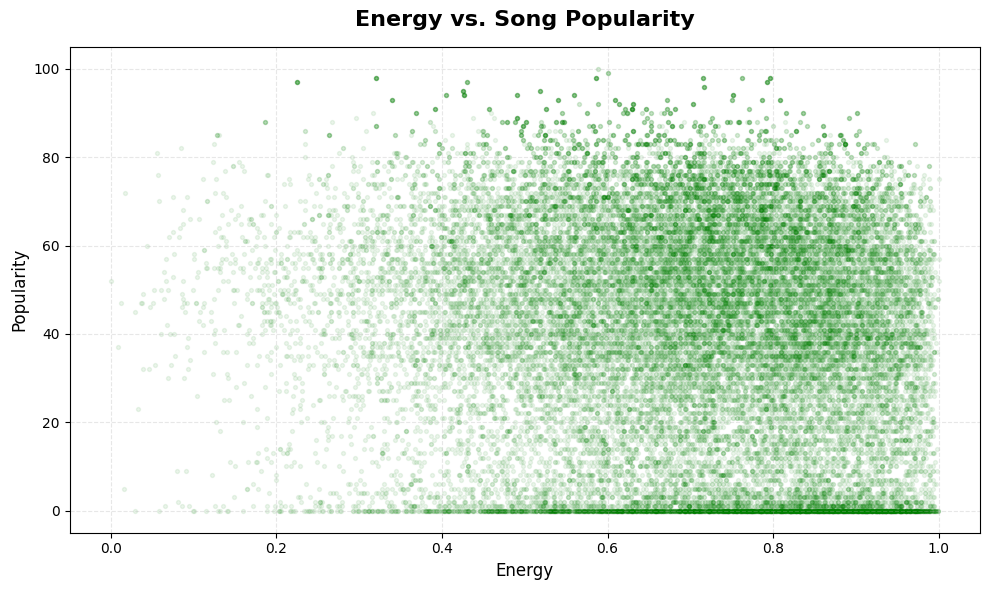

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df["energy"],
    df["track_popularity"],
    s=8,
    color="green",
    alpha=0.08
)
plt.title(
    "Energy vs. Song Popularity",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Energy", fontsize=12)
plt.ylabel("Popularity", fontsize=12)
plt.grid(
    linestyle="--",
    alpha=0.3
)
plt.tight_layout()
plt.show()

A scatter plot is useful when we want to investigate a relationship between two numerical variables. However, visualizing a large dataset requires more than simply plotting every observation.

When a visualization becomes too crowded, we can use techniques such as:

- reducing marker size
- increasing transparency
- adding a trend line
- grouping observations
- summarizing the data

The right approach depends on the question we are trying to answer.

Most importantly, visualization should help us explore the data rather than force a conclusion. If the relationship between energy and popularity is weak, that is still a meaningful finding.

# Box Plot: Comparing Popularity Across Genres

## Creating a Basic Box Plot

First, we use unique() to retrieve all distinct genres and sorted() to arrange them alphabetically. Then, we create a list comprehension that filters the DataFrame for each genre and extracts its track_popularity values. The resulting data_groups list contains a separate group of popularity scores for each genre, ready to be used in the box plot.

In [ ]:
all_genres = sorted(df["playlist_genre"].unique())
data_groups = [
    df[df["playlist_genre"] == genre]["track_popularity"]
    for genre in all_genres
]

Let's compare the popularity of songs across genres.

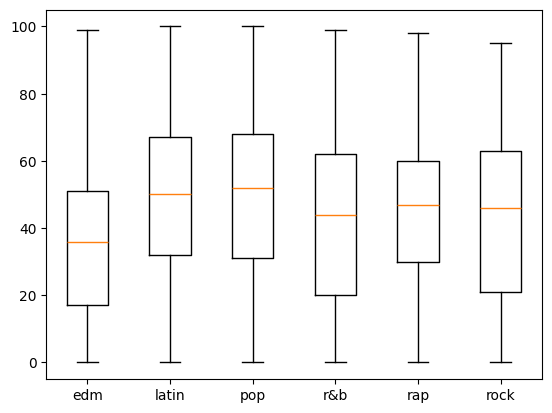

In [ ]:
plt.boxplot(
    data_groups,
    tick_labels=all_genres
)
plt.show()

The resulting box plot allows us to compare the popularity distributions of these genres.

## Understanding a Box Plot
A box plot may look unfamiliar at first, but each part represents useful information:
- The line inside the box represents the median.
- The box represents the middle 50% of the data, known as the interquartile range (IQR).
- The whiskers extend toward the lower and upper values within the typical range.
- Points beyond the whiskers may represent potential outliers.

This makes box plots particularly useful when we want to understand not just the average value, but the spread and variability of the data.

## A More Polished Box Plot
As with our previous charts, we can improve readability by adjusting the figure size, labels, title, and grid.

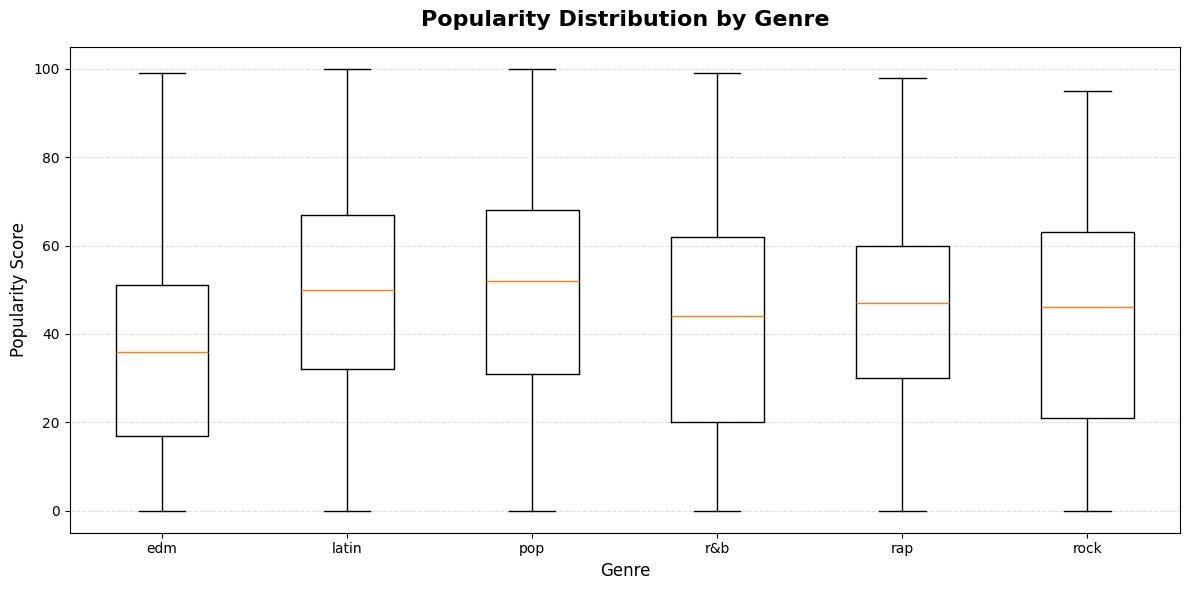

In [ ]:
plt.figure(figsize=(12, 6))
plt.boxplot(
    data_groups,
    tick_labels=all_genres
)
plt.title(
    "Popularity Distribution by Genre",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Genre", fontsize=12)
plt.ylabel("Popularity Score", fontsize=12)
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)
plt.tight_layout()
plt.show()

These small adjustments make the chart easier to interpret without adding unnecessary visual elements.

## A More Useful Comparison
One advantage of a box plot is that it shows information that a simple bar chart might hide.

For example, two genres could have similar average popularity but very different distributions. One genre might have songs with consistently similar popularity, while another might have a much wider range.

This is why choosing the right visualization matters. A bar chart is useful when we want to compare a single value across categories, while a box plot is better when we want to compare the distribution of a numerical variable across groups.

In our Spotify dataset, the box plot gives us a more detailed view of how song popularity varies between genres.

# Pie Chart: Genre Proportions

## Creating a Basic Pie Chart

First, we need to count the number of songs in each genre.

In [ ]:
genre_counts = df.groupby("playlist_genre")["track_id"].count()

Next, we can create a basic pie chart.

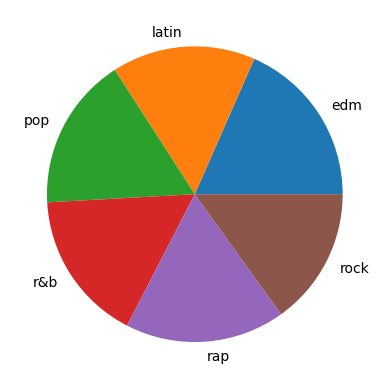

In [ ]:
plt.pie(
    genre_counts,
    labels=genre_counts.index
)
plt.show()

The plt.pie() function creates a slice for each genre, with the size of each slice proportional to its share of the total number of songs. The labels parameter displays the genre names next to their corresponding slices.

This gives us a basic overview of the distribution. However, adding percentages and adjusting the layout can make the chart easier to interpret.

## A More Polished Pie Chart
Let's improve the visualization by displaying percentages, highlighting one slice, and positioning a legend beside the chart.

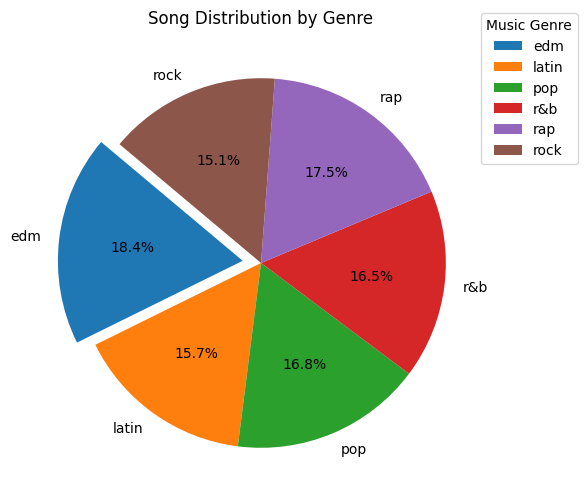

In [ ]:
max_index = genre_counts.values.argmax()
exp = [0.1 if i == max_index else 0 for i in range(len(genre_counts))]
plt.figure(figsize=(8, 6))
plt.pie(
    genre_counts,
    labels=genre_counts.index,
    explode=exp,
    autopct="%1.1f%%",
    startangle=140)
plt.legend(
    bbox_to_anchor=(1.2,0.7),
    title="Music Genre",
    loc="lower right")
plt.title("Song Distribution by Genre")
plt.show()

# Bringing All Visualizations Together

Throughout this notebook, we have used six different plot types to explore the Spotify dataset:

* Line charts helped us visualize changes in average song duration over time.
* Bar charts helped us compare the average speechiness across genres.
* Histograms helped us understand the distribution of song durations.
* Scatter plots helped us explore the relationship between energy and popularity.
* Box plots helped us compare popularity distributions across genres.
* Pie charts helped us visualize the proportion of songs belonging to each genre.

Although each plot serves a different purpose, they all demonstrate the flexibility of Matplotlib and the importance of choosing the right visualization for the question at hand.
To see how these visualizations complement one another, let's combine them into a single figure.

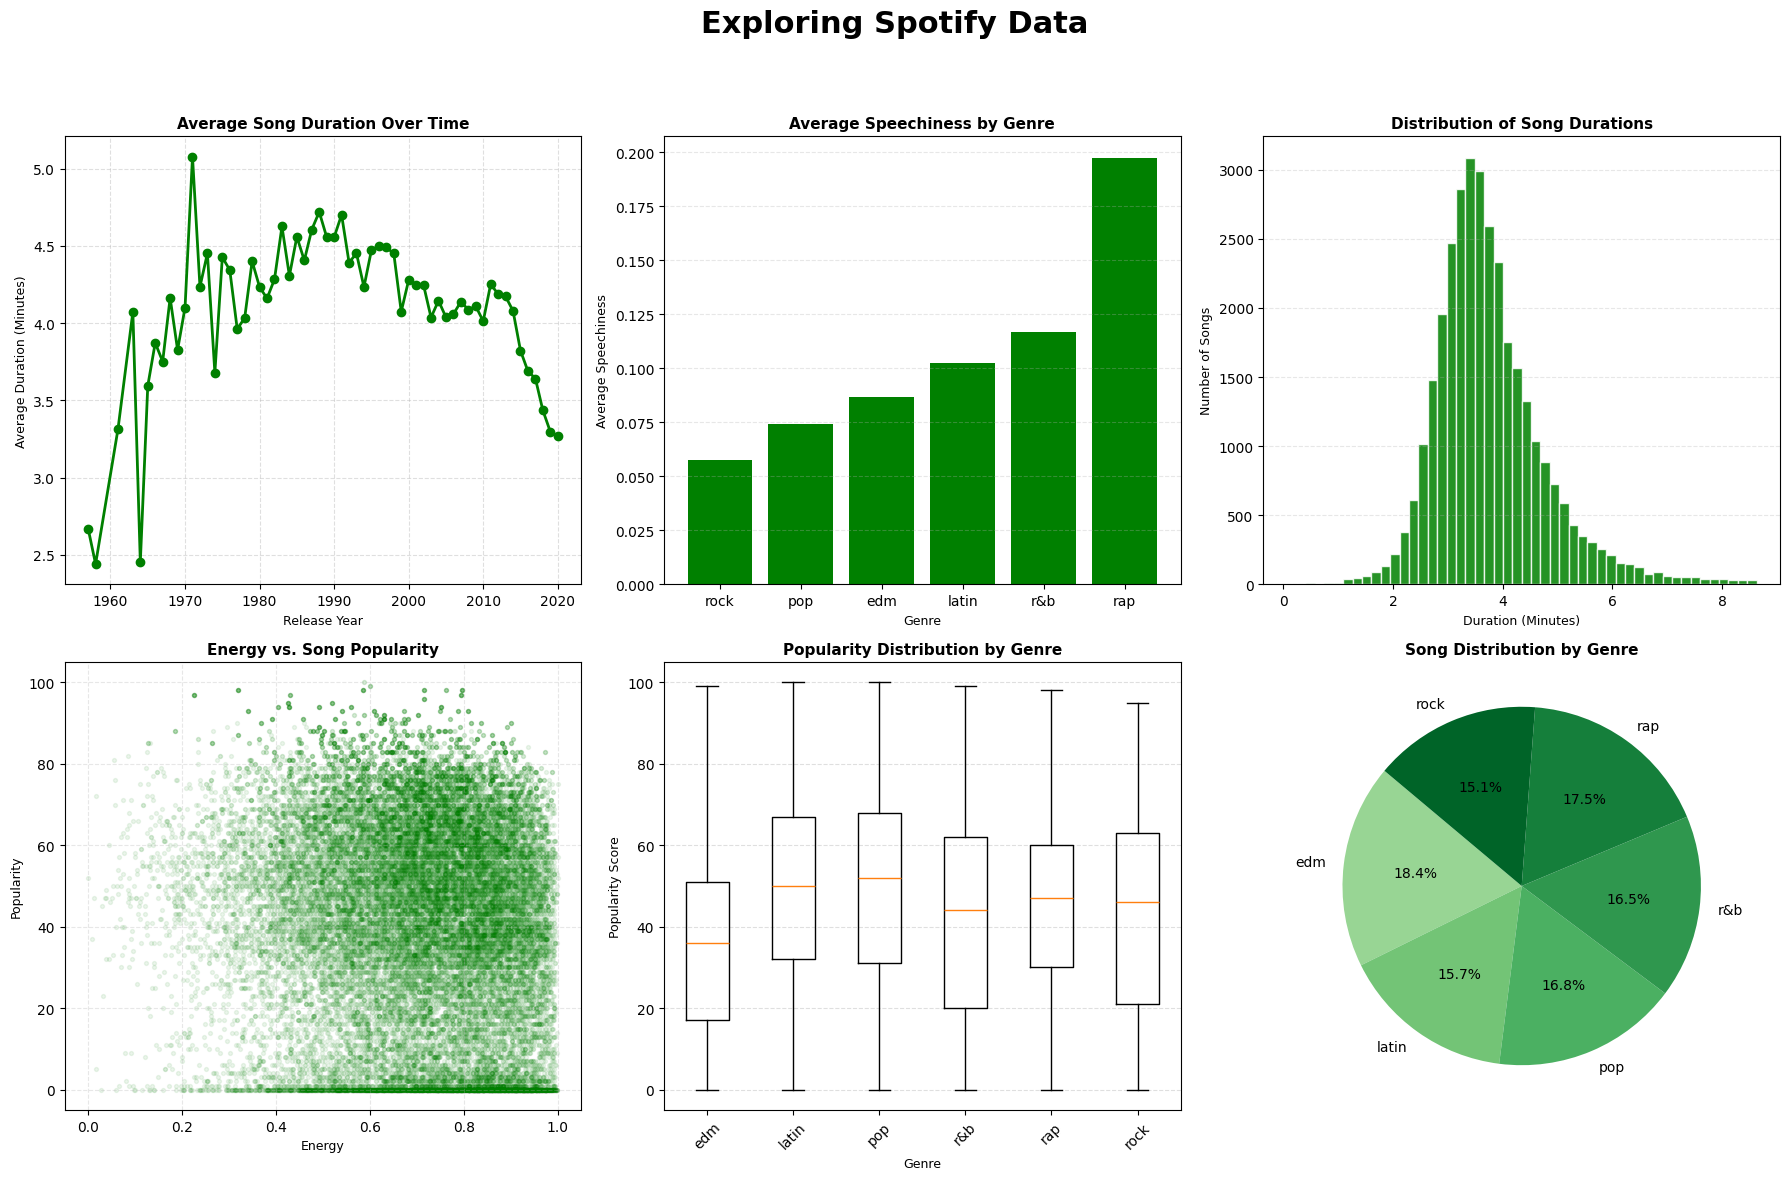

In [ ]:
# Create the 2x3 subplots figure
fig, axs = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("Exploring Spotify Data", fontsize=22, fontweight="bold")

# 1. Line Plot (Top Left: 0,0)
axs[0, 0].plot(
    years,
    average_duration,
    marker="o",
    color="green",
    linestyle="-",
    linewidth=2
)
axs[0, 0].set_title("Average Song Duration Over Time", fontsize=11, fontweight="bold")
axs[0, 0].set_xlabel("Release Year", fontsize=9)
axs[0, 0].set_ylabel("Average Duration (Minutes)", fontsize=9)
axs[0, 0].grid(True, linestyle="--", alpha=0.4)

# 2. Bar Chart (Top Middle: 0,1)
bars = axs[0, 1].bar(
    genre_speechiness.index,
    genre_speechiness.values,
    color="green"
)
axs[0, 1].set_title("Average Speechiness by Genre", fontsize=11, fontweight="bold")
axs[0, 1].set_xlabel("Genre", fontsize=9)
axs[0, 1].set_ylabel("Average Speechiness", fontsize=9)
axs[0, 1].grid(axis="y", linestyle="--", alpha=0.3)

# 3. Histogram (Top Right: 0,2)
axs[0, 2].hist(
    duration_mins,
    bins=50,
    color="green",
    edgecolor="white",
    alpha=0.85
)
axs[0, 2].set_title("Distribution of Song Durations", fontsize=11, fontweight="bold")
axs[0, 2].set_xlabel("Duration (Minutes)", fontsize=9)
axs[0, 2].set_ylabel("Number of Songs", fontsize=9)
axs[0, 2].grid(axis="y", linestyle="--", alpha=0.3)

# 4. Scatter Plot (Bottom Left: 1,0)
axs[1, 0].scatter(
    df["energy"],
    df["track_popularity"],
    s=8,
    color="green",
    alpha=0.08
)
axs[1, 0].set_title("Energy vs. Song Popularity", fontsize=11, fontweight="bold")
axs[1, 0].set_xlabel("Energy", fontsize=9)
axs[1, 0].set_ylabel("Popularity", fontsize=9)
axs[1, 0].grid(linestyle="--", alpha=0.3)

# 5. Box Plot (Bottom Middle: 1,1)
axs[1, 1].boxplot(
    data_groups,
    tick_labels=all_genres
)
axs[1, 1].set_title("Popularity Distribution by Genre", fontsize=11, fontweight="bold")
axs[1, 1].set_xlabel("Genre", fontsize=9)
axs[1, 1].set_ylabel("Popularity Score", fontsize=9)
axs[1, 1].tick_params(axis="x", rotation=45)
axs[1, 1].grid(axis="y", linestyle="--", alpha=0.4)

# 6. Pie Chart (Bottom Right: 1,2)
axs[1, 2].pie(
    genre_counts,
    labels=genre_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=plt.cm.Greens(np.linspace(0.4, 0.9, len(genre_counts)))
)
axs[1, 2].set_title("Song Distribution by Genre", fontsize=11, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

We can combine multiple charts into one figure using plt.subplots(). Here, plt.subplots(2, 3) creates a grid with two rows and three columns, giving us six spaces for our visualizations. The figsize parameter controls the overall figure size, while fig.suptitle() adds a title to the entire figure.

Each chart is then created in its own subplot using axs[row, column]. For example, axs[0, 0] refers to the top-left position, where we place the line chart. This approach allows us to compare six visualizations side by side while keeping them organized within a single figure.

The line chart shows how average song duration has changed over time, while the bar chart compares the average speechiness across genres. The histogram reveals the distribution of song durations, the scatter plot explores the relationship between energy and popularity, the box plot highlights differences in popularity distributions across genres, and the pie chart illustrates each genre's share of the dataset.

Together, these charts allow us to examine the dataset from multiple perspectives. For example, the scatter plot suggests that energy alone is not a strong predictor of popularity, while the box plot reveals differences in median popularity between genres.

The key takeaway is that no single chart tells the whole story. By combining different visualizations, we can gain a more comprehensive understanding of a dataset and communicate our findings more effectively.